In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\RU-ECE-118-15\Downloads\powerconsumption.csv")

print(df.head())
print(df.info())
print(df.columns)
print(df.isnull().sum())


        Datetime  Temperature  Humidity  WindSpeed  GeneralDiffuseFlows  \
0  1/1/2017 0:00        6.559      73.8      0.083                0.051   
1  1/1/2017 0:10        6.414      74.5      0.083                0.070   
2  1/1/2017 0:20        6.313      74.5      0.080                0.062   
3  1/1/2017 0:30        6.121      75.0      0.083                0.091   
4  1/1/2017 0:40        5.921      75.7      0.081                0.048   

   DiffuseFlows  PowerConsumption_Zone1  PowerConsumption_Zone2  \
0         0.119             34055.69620             16128.87538   
1         0.085             29814.68354             19375.07599   
2         0.100             29128.10127             19006.68693   
3         0.096             28228.86076             18361.09422   
4         0.085             27335.69620             17872.34043   

   PowerConsumption_Zone3  
0             20240.96386  
1             20131.08434  
2             19668.43373  
3             18899.27711  
4     

In [2]:
df["Datetime"] = pd.to_datetime(df["Datetime"])
df = df.sort_values("Datetime")
df.head()


,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [3]:
target = df[["PowerConsumption_Zone1"]]
target.head()

,PowerConsumption_Zone1
0,34055.69620
1,29814.68354
2,29128.10127
3,28228.86076
4,27335.69620


In [5]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(target)
train_size = int(len(scaled_data) * 0.8)
train = scaled_data[:train_size]
test = scaled_data[train_size:]


In [6]:
import numpy as np

def create_sequences(data, lookback):
    X = []
    y = []

    for i in range(len(data) - lookback):
        X.append(data[i:i+lookback])
        y.append(data[i+lookback])

    return np.array(X), np.array(y)

lookback = 30
X_train, y_train = create_sequences(train, lookback)
X_test, y_test = create_sequences(test, lookback)
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)


(41902, 30, 1)
(41902, 1)
(10454, 30, 1)
(10454, 1)


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

lstm_model = Sequential([
    LSTM(64,input_shape=(30,1)),
    Dense(32, activation="relu"),
    Dense(1)
])
lstm_model.summary()


Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_1 (LSTM)               (None, 64)                16896     
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 1)                 33        
                                                                 
Total params: 19009 (74.25 KB)
Trainable params: 19009 (74.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [9]:
lstm_model.compile(optimizer="adam",loss="mse",metrics=["mae"])
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    )

]

history_lstm = lstm_model.fit(

    X_train,
    y_train,

    validation_data=(X_test,y_test),

    epochs=10,

    batch_size=32,

    callbacks=callbacks

)


Epoch 1/10
1310/1310 [==============================] - 16s 10ms/step - loss: 0.0021 - mae: 0.0217 - val_loss: 2.2514e-04 - val_mae: 0.0091 - lr: 0.0010
Epoch 2/10
1310/1310 [==============================] - 13s 10ms/step - loss: 2.3523e-04 - mae: 0.0102 - val_loss: 1.5560e-04 - val_mae: 0.0081 - lr: 0.0010
Epoch 3/10
1310/1310 [==============================] - 12s 9ms/step - loss: 1.7948e-04 - mae: 0.0089 - val_loss: 1.2155e-04 - val_mae: 0.0080 - lr: 0.0010
Epoch 4/10
1310/1310 [==============================] - 12s 9ms/step - loss: 1.6268e-04 - mae: 0.0085 - val_loss: 1.1777e-04 - val_mae: 0.0072 - lr: 0.0010
Epoch 5/10
1310/1310 [==============================] - 12s 9ms/step - loss: 1.6058e-04 - mae: 0.0085 - val_loss: 1.1132e-04 - val_mae: 0.0070 - lr: 0.0010
Epoch 6/10
1310/1310 [==============================] - ETA: 0s - loss: 1.5471e-04 - mae: 0.0082
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1310/1310 [==============================] - 13s 

In [10]:
loss_lstm, mae_lstm = lstm_model.evaluate(X_test, y_test, verbose=0)

print("LSTM Loss :", loss_lstm)
print("LSTM MAE  :", mae_lstm)


LSTM Loss : 0.00010741846926975995
LSTM MAE  : 0.007260622922331095


In [11]:
from tensorflow.keras.layers import Bidirectional, LSTM, Dense
from tensorflow.keras.models import Sequential
bilstm_model = Sequential([
    Bidirectional(LSTM(64),input_shape=(30,1)),
    Dense(32, activation="relu"),
    Dense(1)
])
bilstm_model.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 bidirectional (Bidirection  (None, 128)               33792     
 al)                                                             
                                                                 
 dense_4 (Dense)             (None, 32)                4128      
                                                                 
 dense_5 (Dense)             (None, 1)                 33        
                                                                 
Total params: 37953 (148.25 KB)
Trainable params: 37953 (148.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [12]:
bilstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
history_bilstm = bilstm_model.fit(X_train,y_train,validation_data=(X_test, y_test),epochs=10,batch_size=32,callbacks=callbacks)


Epoch 1/10
1310/1310 [==============================] - 20s 11ms/step - loss: 0.0026 - mae: 0.0239 - val_loss: 2.5843e-04 - val_mae: 0.0104 - lr: 0.0010
Epoch 2/10
1310/1310 [==============================] - 13s 10ms/step - loss: 2.3942e-04 - mae: 0.0105 - val_loss: 1.8668e-04 - val_mae: 0.0107 - lr: 0.0010
Epoch 3/10
1310/1310 [==============================] - 13s 10ms/step - loss: 1.8342e-04 - mae: 0.0092 - val_loss: 1.1455e-04 - val_mae: 0.0072 - lr: 0.0010
Epoch 4/10
1310/1310 [==============================] - 11s 9ms/step - loss: 1.6274e-04 - mae: 0.0086 - val_loss: 2.1154e-04 - val_mae: 0.0120 - lr: 0.0010
Epoch 5/10
1310/1310 [==============================] - 11s 8ms/step - loss: 1.5517e-04 - mae: 0.0084 - val_loss: 1.0204e-04 - val_mae: 0.0067 - lr: 0.0010
Epoch 6/10
1302/1310 [============================>.] - ETA: 0s - loss: 1.5286e-04 - mae: 0.0083
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
1310/1310 [==============================] - 11s

In [13]:
print(callbacks)

[<keras.src.callbacks.EarlyStopping object at 0x000002802AF71A90>, <keras.src.callbacks.ReduceLROnPlateau object at 0x000002802B01FEE0>]


In [14]:
loss_bilstm, mae_bilstm = bilstm_model.evaluate(X_test, y_test, verbose=0)

print("Bidirectional LSTM Loss:", loss_bilstm)
print("Bidirectional LSTM MAE :", mae_bilstm)


Bidirectional LSTM Loss: 9.667022823123261e-05
Bidirectional LSTM MAE : 0.006618097424507141


In [15]:
comparison = pd.DataFrame({

    "Model":[
        "LSTM",
        "Bidirectional LSTM"
    ],

    "Loss":[
        loss_lstm,
        loss_bilstm
    ],

    "MAE":[
        mae_lstm,
        mae_bilstm
    ]

})
comparison

,Model,Loss,MAE
0,LSTM,0.000107,0.007261
1,Bidirectional LSTM,0.000097,0.006618


327/327 [==============================] - 3s 10ms/step


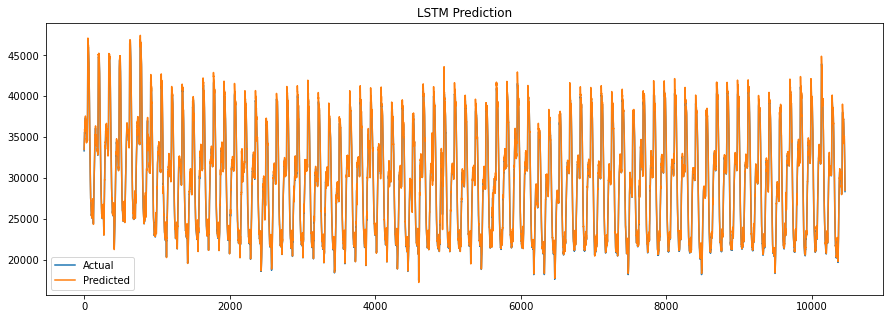

In [17]:
pred_lstm = lstm_model.predict(X_test)
pred_lstm = scaler.inverse_transform(pred_lstm)
actual = scaler.inverse_transform(y_test)
import matplotlib.pyplot as plt
plt.figure(figsize=(15,5))
plt.plot(actual,label="Actual")
plt.plot(pred_lstm,label="Predicted")
plt.legend()
plt.title("LSTM Prediction")
plt.show()


327/327 [==============================] - 2s 3ms/step


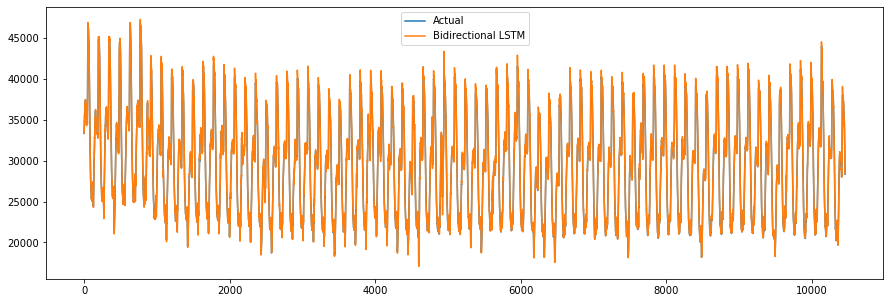

In [18]:
pred_bilstm = bilstm_model.predict(X_test)
pred_bilstm = scaler.inverse_transform(pred_bilstm)
plt.figure(figsize=(15,5))
plt.plot(actual,label="Actual")
plt.plot(pred_bilstm,label="Bidirectional LSTM")
plt.legend()
plt.show()

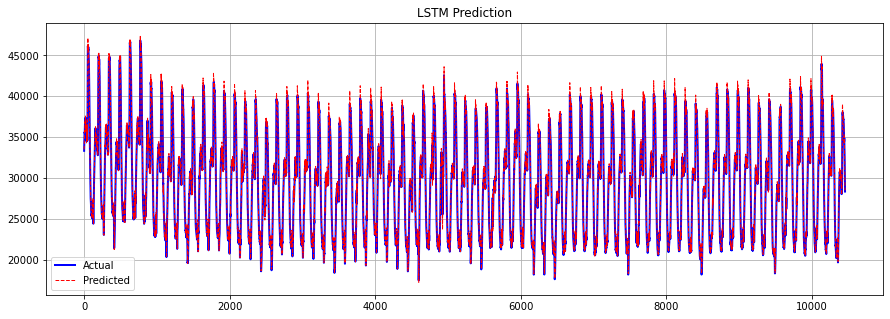

In [19]:
plt.figure(figsize=(15,5))
plt.plot(actual, label="Actual", color="blue", linewidth=2)
plt.plot(pred_lstm,
         label="Predicted",
         color="red",
         linestyle="--",
         linewidth=1)
plt.legend()
plt.title("LSTM Prediction")
plt.grid(True)
plt.show()
